#### Readme note: 
Since this task focuses on data sense, reviewing the audit log for each step would be much more helpful.
Currently, I have these functions scattered throughout the codebase to print log on current notebook window. 
```
inspect_bronze_data()

inspect_silver_load()

inspect_gold_load()
```

Rendering the visualization might take a bit long since it generates heavy HTML.

# Overview: Clean Customer Transactions


### Use Case: Guarantee data quality for customer transaction reporting


Flow:

```text
CSV File
   ↓
Bronze (Raw Data)
   ↓
Data Quality Checks
   ↓
Silver (Deduplicated Data)
   ↓
Gold (Aggregated Reports)
   ↓
Visualization
```

---

# Source Data

File: amazon_customer_transactions.csv

---

# Bronze Layer

## Table

#### bronze_raw

Stores raw transactions with ingestion metadata.

## Functions

#### load_bronze(conn, csv_path)

Loads raw data into `bronze_raw`.

#### inspect_bronze_data()

Validates:

- Data types
- Missing values
- Negative values
- Zero amounts
- Processing duration > 60 minutes
- Product price consistency
- Exact duplicate rows
- Duplicate transaction IDs with conflicting values

### Issues Found

Exact duplicates (100% identical)

Conflicting transaction_IDs (Partial duplicate)


# Silver Layer

## Tables

#### silver_transactions

Cleaned and deduplicated transactions.

#### silver_transaction_quarantine

Stores records that require investigation.

## Rules

| Scenario | Action |
|-----------|----------|
| Valid record | Load to Silver |
| Exact duplicate | Keep one record |
| Duplicate conflict | Quarantine older version |
| Missing field | Quarantine |
| Negative amount | Quarantine |
| Zero amount | Quarantine |

## Functions

#### load_silver()

1. Remove exact duplicates.
2. Detect transaction conflicts.
3. Move outdated records to quarantine.
4. Keep the latest version using `recorded_at`.

#### inspect_silver_load()

Audits:
- Removed duplicates
- Quarantined records
- Conflict resolution decisions
---

# Gold Layer

## Table

#### gold_daily_product_revenue

Columns:

| Column | Description |
|----------|----------|
| order_date | Transaction date |
| product | Product name |
| transaction_count | Number of transactions |
| revenue | Total revenue |


#### load_gold()

Builds aggregated metrics from Silver.


#### inspect_gold_load()

Validates:

- Total revenue
- Total transactions
- Dataset grain
- Top products
- Top revenue days

---

# Key Notes

- Gold is built only from Silver.
- Duplicate transactions are removed before aggregation.
- Each transaction contributes to revenue exactly once.
- Quarantine records are kept for auditing and troubleshooting.
- Re-running the pipeline does not cause double counting.

---

# Execution Order

```python
load_bronze()
inspect_bronze_data()

load_silver()
inspect_silver_load()

load_gold()
inspect_gold_load()

```

# Visualization for 'daily revenue' and 'revenue by product'. 
Drawing charts using Python built-ins

# Begin

In [1]:
from pathlib import Path
import sqlite3
from datetime import datetime, UTC

import pandas as pd

DATA_FILE =  Path("amazon_customer_transactions.csv")
DB_PATH = Path("data.db")
df = pd.read_csv(DATA_FILE)
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

def ingest_source(path, source_file='source'):
    # load CSV or Excel
    if str(path).lower().endswith(('.xls', '.xlsx')):
        df = pd.read_excel(path)
    else:
        df = pd.read_csv(path)
    # normalize columns
    expected = ['transaction_id','customer_id','product','amount','order_timestamp','recorded_at']
    df = df.rename(columns={c:c.strip() for c in df.columns})
    # add metadata
    df['source_file'] = source_file
    df['batch_id'] = datetime.utcnow().isoformat()
    df['ingested_at'] = datetime.utcnow()
    return df

In [2]:
def init_tables(conn: sqlite3.Connection) -> None:
    conn.executescript(
        
        """
        CREATE TABLE IF NOT EXISTS bronze_raw (
            transaction_id TEXT,
            customer_id TEXT,
            product TEXT,
            amount REAL,
            order_timestamp TEXT,
            recorded_at TEXT,
            source_file TEXT,
            batch_id TEXT,
            ingested_at TEXT
        );
        """
    )
def load_bronze(conn: sqlite3.Connection, csv_path: Path) -> pd.DataFrame:
    raw_df = pd.read_csv(csv_path)
    bronze_df = raw_df.copy()
    bronze_df["source_file"] = str(csv_path)
    bronze_df["batch_id"] = datetime.now(UTC).isoformat()
    bronze_df["ingested_at"] = datetime.now(UTC).isoformat()
    bronze_df.to_sql("bronze_raw", conn, if_exists="replace", index=False)
    return bronze_df

conn = sqlite3.connect(DB_PATH)
init_tables(conn)
bronze_df = load_bronze(conn, DATA_FILE)    
print(f"Bronze rows loaded: {len(bronze_df)}")

Bronze rows loaded: 81


In [3]:
cur.execute(f"SELECT * FROM bronze_raw")
headers = [desc[0] for desc in cur.description]
rows = cur.fetchall()

print("=== HEADER ===")
print(" | ".join(headers))
print("-" * 80)

print(f"Total rows: {len(rows)}\n")
for row in rows:
    print(row)

=== HEADER ===
transaction_id | customer_id | product | amount | order_timestamp | recorded_at | source_file | batch_id | ingested_at
--------------------------------------------------------------------------------
Total rows: 81

(8113, 311, 'Phone Case', 21, '2026-05-03 16:45', '2026-05-03 16:48', 'amazon_customer_transactions.csv', '2026-10-01T08:01:53.086001+00:00', '2026-10-01T08:01:53.090265+00:00')
(8118, 318, 'Webcam', 79, '2026-05-05 10:23', '2026-05-05 10:25', 'amazon_customer_transactions.csv', '2026-10-01T08:01:53.086001+00:00', '2026-10-01T08:01:53.090265+00:00')
(8107, 316, 'Yoga Mat', 29, '2026-05-02 20:33', '2026-05-02 20:35', 'amazon_customer_transactions.csv', '2026-10-01T08:01:53.086001+00:00', '2026-10-01T08:01:53.090265+00:00')
(8137, 302, 'Webcam', 79, '2026-05-16 23:36', '2026-05-16 23:38', 'amazon_customer_transactions.csv', '2026-10-01T08:01:53.086001+00:00', '2026-10-01T08:01:53.090265+00:00')
(8133, 304, 'Office Chair', 230, '2026-05-14 14:20', '2026-05-14 14

### Data Quality Checks Report Checklist
- Check data types.
- Check missing values.
- Check negative numeric values.
- Check zero amounts.
- Check long processing times (> 60 minutes).
- Check product price consistency.
- Check exact duplicate rows.
- Check duplicate transaction IDs with conflicting values.
- Display affected records for troubleshooting.

In [4]:
def inspect_bronze_data(table_name: str = "bronze_raw") -> None:
    import pandas as pd

    query = f"SELECT * FROM {table_name}"
    frame = pd.read_sql_query(query, conn)

    print("=" * 60)
    print(f"DATA QUALITY REPORT: {table_name}")
    print("=" * 60)
    print(f"Total rows: {len(frame)}")
    print(f"Total columns: {len(frame.columns)}")

    print("\n" + "=" * 60)
    print("1. DATA TYPES")
    print("=" * 60)
    print(frame.dtypes.to_string())

    print("\n" + "=" * 60)
    print("2. MISSING VALUES")
    print("=" * 60)

    null_counts = frame.isna().sum()
    missing_data = null_counts[null_counts > 0]

    if not missing_data.empty:
        for col, count in missing_data.items():
            pct = count / len(frame) * 100
            print(f"\n- Column '{col}': {count} missing values ({pct:.2f}%)")
            print(frame[frame[col].isna()].head(10).to_string(index=False))
    else:
        print("✅ No missing values found.")

    print("\n" + "=" * 60)
    print("3. DATA QUALITY & BUSINESS ANOMALY CHECKS")
    print("=" * 60)

    has_issues = False

    # 3.1 Negative / Zero Values
    numeric_columns = frame.select_dtypes(include="number").columns.tolist()
    for col in numeric_columns:
        negative_rows = frame[frame[col] < 0]
        if not negative_rows.empty:
            print(f"\n- Column '{col}': {len(negative_rows)} negative values")
            print(negative_rows.head(10).to_string(index=False))
            has_issues = True

        if "amount" in col.lower():
            zero_rows = frame[frame[col] == 0]
            if not zero_rows.empty:
                print(f"\n- Column '{col}': {len(zero_rows)} zero values")
                print(zero_rows.head(10).to_string(index=False))
                has_issues = True

    # 3.2 Long Processing Duration
    datetime_candidates = [
        ("order_timestamp", "recorded_at"),
        ("created_at", "updated_at"),
        ("order_time", "processed_time"),
    ]

    for start_col, end_col in datetime_candidates:
        if {start_col, end_col}.issubset(frame.columns):
            tmp = frame.copy()
            tmp[start_col] = pd.to_datetime(tmp[start_col], errors="coerce")
            tmp[end_col] = pd.to_datetime(tmp[end_col], errors="coerce")
            tmp["duration_minutes"] = (tmp[end_col] - tmp[start_col]).dt.total_seconds() / 60

            long_transactions = tmp[tmp["duration_minutes"] > 60]
            if not long_transactions.empty:
                print(f"\n- {len(long_transactions)} transactions exceeded 60 minutes processing time")
                cols = [c for c in ["transaction_id", "customer_id", "product", "amount", "duration_minutes"] if c in long_transactions.columns]
                print(long_transactions[cols].head(10).to_string(index=False))
                has_issues = True
            break

    # 3.3 Product Price Inconsistency
    if {"product", "amount"}.issubset(frame.columns):
        inconsistent_products = frame.groupby("product")["amount"].nunique().reset_index(name="price_versions")
        inconsistent_products = inconsistent_products[inconsistent_products["price_versions"] > 1]

        if not inconsistent_products.empty:
            print("\n- Products with inconsistent pricing:")
            for product in inconsistent_products["product"]:
                product_rows = frame[frame["product"] == product].sort_values("amount")
                prices = product_rows["amount"].dropna().unique().tolist()
                print(f"\nProduct: {product}\nObserved prices: {prices}")
                cols = [c for c in ["transaction_id", "customer_id", "product", "amount"] if c in product_rows.columns]
                print(product_rows[cols].head(10).to_string(index=False))
            has_issues = True

    if not has_issues:
        print("✅ No issues detected.")

    print("\n" + "=" * 60)
    print("4. DUPLICATE ANALYSIS")
    print("=" * 60)

    if "transaction_id" in frame.columns:
        # A. Exact Duplicate Rows
        exact_duplicates = frame[frame.duplicated(keep=False)]
        print(f"\nA. Exact Duplicate Rows\n- Rows involved: {len(exact_duplicates)}")
        if not exact_duplicates.empty:
            print(exact_duplicates.head(10).to_string(index=False))

        # B. Duplicate IDs with Conflicting Values
        conflicting_ids = []
        for tid, grp in frame.groupby("transaction_id"):
            if len(grp) <= 1:
                continue
            compare_cols = [c for c in frame.columns if c != "transaction_id"]
            if any(grp[col].nunique(dropna=False) > 1 for col in compare_cols):
                conflicting_ids.append(tid)

        print(f"\nB. Duplicate IDs with Conflicting Values\n- Affected transaction IDs: {len(conflicting_ids)}")
        if conflicting_ids:
            print(f"- Example transaction IDs: {conflicting_ids[:10]}")
            conflict_rows = frame[frame["transaction_id"].isin(conflicting_ids)]
            print(conflict_rows.sort_values("transaction_id").head(20).to_string(index=False))
    else:
        print("⚠️ transaction_id column not found. Duplicate analysis skipped.")

    print("\n✅ Data quality inspection completed.")

In [5]:
# Generate report result
inspect_bronze_data('bronze_raw')

DATA QUALITY REPORT: bronze_raw
Total rows: 81
Total columns: 9

1. DATA TYPES
transaction_id     int64
customer_id        int64
product              str
amount             int64
order_timestamp      str
recorded_at          str
source_file          str
batch_id             str
ingested_at          str

2. MISSING VALUES
✅ No missing values found.

3. DATA QUALITY & BUSINESS ANOMALY CHECKS

- 2 transactions exceeded 60 minutes processing time
 transaction_id  customer_id    product  amount  duration_minutes
           8123          319 Phone Case      30             361.0
           8157          305  Desk Lamp      33             363.0

- Products with inconsistent pricing:

Product: Desk Lamp
Observed prices: [33, 38]
 transaction_id  customer_id   product  amount
           8157          305 Desk Lamp      33
           8169          322 Desk Lamp      38
           8159          312 Desk Lamp      38
           8146          314 Desk Lamp      38
           8129          304 Desk L

## Silver Layer: Data Cleaning and Transformation


## Final Migration Decision Matrix
| Scenario | Action |
| :--- | :--- |
| **Valid record** | Load to Silver |
| **Exact duplicate row** | Keep one, remove duplicates |
| **Duplicate transaction_id with conflicting values** | Quarantine all versions |
| **Missing required field** | Quarantine |
| **Negative amount** | Quarantine |
| **Zero amount** | Quarantine |
| **Long processing time** | Load to Silver + flag |
| **Product price inconsistency** | Investigate / flag |

In [6]:
def init_tables(conn: sqlite3.Connection) -> None:
    conn.executescript(
        """
	    CREATE TABLE IF NOT EXISTS silver_transactions (
		transaction_id TEXT,
		customer_id TEXT,
		product TEXT,
		amount REAL,
		order_timestamp TEXT,
		recorded_at TEXT,
		source_file TEXT,
		batch_id TEXT,
		ingested_at TEXT
		
        );
        """,
        """
        CREATE TABLE IF NOT EXISTS silver_transaction_quarantine (
        quarantine_id INTEGER PRIMARY KEY AUTOINCREMENT,
         
        transaction_id TEXT,
        customer_id TEXT,
        product TEXT,
        amount REAL,
        order_timestamp TEXT,
        recorded_at TEXT,
        source_file TEXT,
        batch_id TEXT,
        ingested_at TEXT,
         
        quarantine_reason TEXT,
        failed_rule TEXT,
         
        quarantined_at TEXT DEFAULT CURRENT_TIMESTAMP
        );
        """
    )
    
def load_silver(conn: sqlite3.Connection) -> pd.DataFrame:
    import pandas as pd

    # Load bronze data & convert timestamp
    bronze_df = pd.read_sql_query("SELECT * FROM bronze_raw", conn)
    bronze_df["recorded_at"] = pd.to_datetime(bronze_df["recorded_at"])

    # 1. Remove exact duplicate rows
    bronze_df = bronze_df.drop_duplicates()

    # 2. Detect conflicting transaction_ids
    quarantine_rows = []
    compare_cols = [c for c in bronze_df.columns if c not in ("transaction_id", "recorded_at", "ingested_at", "batch_id")]

    for tid, grp in bronze_df.groupby("transaction_id"):
        if len(grp) > 1 and any(grp[col].nunique(dropna=False) > 1 for col in compare_cols):
            grp = grp.sort_values("recorded_at", ascending=False)
            older_versions = grp.iloc[1:].copy()
            older_versions["failed_rule"] = "DUPLICATE_CONFLICT"
            older_versions["quarantine_reason"] = "Superseded by newer record with later recorded_at"
            quarantine_rows.append(older_versions)

    # 3. Write quarantine table
    if quarantine_rows:
        quarantine_df = pd.concat(quarantine_rows, ignore_index=True)
    else:
        quarantine_df = pd.DataFrame(columns=[
            "transaction_id", "customer_id", "product", "amount",
            "order_timestamp", "recorded_at", "source_file", "batch_id",
            "ingested_at", "quarantine_reason", "failed_rule"
        ])
    
    quarantine_df.to_sql("silver_transaction_quarantine", conn, if_exists="replace", index=False)

    # 4. Keep latest record per transaction_id
    silver_df = bronze_df.sort_values("recorded_at").groupby("transaction_id", as_index=False).tail(1)
    silver_df["recorded_at"] = silver_df["recorded_at"].dt.strftime("%Y-%m-%d %H:%M:%S")
    silver_df.to_sql("silver_transactions", conn, if_exists="replace", index=False)

    print(f"Loaded {len(silver_df)} rows into silver_transactions")
    if quarantine_rows:
        print(f"Flagged {len(quarantine_df)} rows into silver_transaction_quarantine")

    return silver_df

conn = sqlite3.connect(DB_PATH)
silver_df = load_silver(conn)

print(f"Silver rows loaded: {len(silver_df)}")

Loaded 76 rows into silver_transactions
Flagged 2 rows into silver_transaction_quarantine
Silver rows loaded: 76


In [7]:
def inspect_silver_load(conn: sqlite3.Connection) -> None:
    import pandas as pd

    bronze_df = pd.read_sql_query("SELECT * FROM bronze_raw", conn)
    silver_df = pd.read_sql_query("SELECT * FROM silver_transactions", conn)
    quarantine_df = pd.read_sql_query("SELECT * FROM silver_transaction_quarantine", conn)

    print("=" * 80)
    print("SILVER LOAD AUDIT REPORT")
    print("=" * 80)
    print(f"Bronze rows      : {len(bronze_df)}")
    print(f"Silver rows      : {len(silver_df)}")
    print(f"Quarantine rows  : {len(quarantine_df)}")

    # 1. QUARANTINED RECORDS
    print("\n" + "=" * 80)
    print("QUARANTINED RECORDS")
    print("=" * 80)
    if quarantine_df.empty:
        print("✅ No records were quarantined.")
    else:
        for _, row in quarantine_df.iterrows():
            print(f"transaction_id={row['transaction_id']} | amount={row['amount']} | rule={row['failed_rule']} | reason={row['quarantine_reason']}")

    # 2. SKIPPED EXACT DUPLICATES
    print("\n" + "=" * 80)
    print("SKIPPED EXACT DUPLICATES")
    print("=" * 80)
    exact_duplicates = bronze_df[bronze_df.duplicated(keep="first")]
    if exact_duplicates.empty:
        print("✅ No exact duplicates skipped.")
    else:
        for _, row in exact_duplicates.iterrows():
            print(f"transaction_id={row['transaction_id']} | skipped because an identical row already exists")

    # 3. CONFLICT RESOLUTION
    print("\n" + "=" * 80)
    print("CONFLICT RESOLUTION DECISIONS")
    print("=" * 80)
    if quarantine_df.empty:
        print("✅ No transaction conflicts detected.")
    else:
        for tid in sorted(quarantine_df["transaction_id"].unique()):
            silver_row = silver_df[silver_df["transaction_id"] == tid]
            quarantine_rows = quarantine_df[quarantine_df["transaction_id"] == tid]

            print(f"\nTransaction ID: {tid}")
            if not silver_row.empty:
                kept = silver_row.iloc[0]
                print(f"KEEP -> amount={kept['amount']} recorded_at={kept['recorded_at']} (latest version)")

            for _, row in quarantine_rows.iterrows():
                print(f"QUARANTINE -> amount={row['amount']} recorded_at={row['recorded_at']}")

    print("\n" + "=" * 80)
    print("AUDIT COMPLETED")
    print("=" * 80)

In [8]:
# Silver Load Quality Report 
inspect_silver_load(conn)

SILVER LOAD AUDIT REPORT
Bronze rows      : 81
Silver rows      : 76
Quarantine rows  : 2

QUARANTINED RECORDS
transaction_id=8123 | amount=21 | rule=DUPLICATE_CONFLICT | reason=Superseded by newer record with later recorded_at
transaction_id=8157 | amount=38 | rule=DUPLICATE_CONFLICT | reason=Superseded by newer record with later recorded_at

SKIPPED EXACT DUPLICATES
transaction_id=8136 | skipped because an identical row already exists
transaction_id=8110 | skipped because an identical row already exists
transaction_id=8162 | skipped because an identical row already exists

CONFLICT RESOLUTION DECISIONS

Transaction ID: 8123
KEEP -> amount=30 recorded_at=2026-05-09 16:13:00 (latest version)
QUARANTINE -> amount=21 recorded_at=2026-05-09 10:13:00

Transaction ID: 8157
KEEP -> amount=33 recorded_at=2026-05-23 20:41:00 (latest version)
QUARANTINE -> amount=38 recorded_at=2026-05-23 14:41:00

AUDIT COMPLETED


# Gold Layer

Purpose: provide a reporting-ready dataset for dashboards.

Source: `silver_transactions`

Gold Grain:
- 1 row per `(order_date, product)`

Columns:

| Column | Source | Description |
|----------|----------|----------|
| order_date | DATE(order_timestamp) | Transaction date |
| product | product | Product name |
| transaction_count | COUNT(transaction_id) | Number of transactions |
| revenue | SUM(amount) | Total revenue |

Rules:
- Build Gold from Silver only.
- Aggregate by `order_date` and `product`.
- Count only deduplicated transactions.
- Sum revenue from deduplicated transactions.

Why this design:
- Supports Daily Revenue reporting.
- Supports Revenue by Product reporting.
- Improves dashboard performance through pre-aggregation.
- Ensures consistent business metrics.
- Prevents revenue double-counting.

Rerun behavior:
- Deduplication happens in Silver.
- Gold is rebuilt from Silver.
- Each transaction contributes to revenue exactly once, even after reruns.

In [9]:

def init_tables(conn: sqlite3.Connection) -> None:
    conn.executescript(
        """
        CREATE TABLE IF NOT EXISTS gold_daily_product_revenue (
            order_date TEXT,
            product TEXT,
            transaction_count INTEGER,
            revenue REAL,
             
            PRIMARY KEY (
            order_date,
            product
            )
            );
        );
        """
    )
    conn.commit()


def load_gold(conn):
    conn.execute("""
        DROP TABLE IF EXISTS gold_daily_product_revenue
    """)

    conn.execute("""
        CREATE TABLE gold_daily_product_revenue AS
        SELECT
            DATE(order_timestamp) AS order_date,
            product,
            COUNT(*) AS transaction_count,
            SUM(amount) AS revenue
        FROM silver_transactions
        GROUP BY
            DATE(order_timestamp),
            product
    """)


conn = sqlite3.connect(DB_PATH)
gold_df = load_gold(conn)
print("Gold table created as placeholder for analytics.")
print(f"Gold rows loaded: {len(silver_df)}")

Gold table created as placeholder for analytics.
Gold rows loaded: 76


In [10]:
def inspect_gold_load(conn: sqlite3.Connection) -> None:
    import pandas as pd

    silver_df = pd.read_sql_query("SELECT * FROM silver_transactions", conn)
    gold_df = pd.read_sql_query("SELECT * FROM gold_daily_product_revenue", conn)

    print("=" * 60)
    print("GOLD LOAD REPORT")
    print("=" * 60)
    print(f"Silver transactions used : {len(silver_df)}")
    print(f"Gold rows created        : {len(gold_df)}")
    print(f"Unique products          : {gold_df['product'].nunique()}")
    print(f"Reporting dates          : {gold_df['order_date'].nunique()}")

    print("\n" + "=" * 60)
    print("METRICS")
    print("=" * 60)
    total_transactions = gold_df["transaction_count"].sum()
    total_revenue = gold_df["revenue"].sum()
    print(f"Total transactions : {total_transactions}")
    print(f"Total revenue      : ${total_revenue:,.2f}")

    print("\n" + "=" * 60)
    print("GRAIN VALIDATION")
    print("=" * 60)
    duplicates = gold_df.duplicated(subset=["order_date", "product"]).sum()
    if duplicates == 0:
        print("✅ Grain validated: 1 row per (order_date, product)")
    else:
        print(f"❌ Found {duplicates} duplicate (order_date, product) records")

    print("\n" + "=" * 60)
    print("DEDUPLICATION VALIDATION")
    print("=" * 60)
    silver_transaction_count = silver_df["transaction_id"].nunique()
    gold_transaction_count = gold_df["transaction_count"].sum()

    print(f"Unique transaction_ids in Silver : {silver_transaction_count}")
    print(f"Transactions counted in Gold     : {gold_transaction_count}")

    if silver_transaction_count == gold_transaction_count:
        print("✅ No transaction double-counting detected")
    else:
        print("❌ Transaction count mismatch detected")

    print("\n" + "=" * 60)
    print("TOP PRODUCTS BY REVENUE")
    print("=" * 60)
    top_products = (
        gold_df.groupby("product", as_index=False)
        .agg(revenue=("revenue", "sum"), transactions=("transaction_count", "sum"))
        .sort_values("revenue", ascending=False)
        .head(10)
    )
    print(top_products.to_string(index=False))

    print("\n" + "=" * 60)
    print("TOP REVENUE DAYS")
    print("=" * 60)
    top_days = (
        gold_df.groupby("order_date", as_index=False)
        .agg(revenue=("revenue", "sum"))
        .sort_values("revenue", ascending=False)
        .head(10)
    )
    print(top_days.to_string(index=False))

    print("\n" + "=" * 60)
    print("GOLD LOAD COMPLETED")
    print("=" * 60)

In [11]:
inspect_gold_load(conn)

GOLD LOAD REPORT
Silver transactions used : 76
Gold rows created        : 65
Unique products          : 15
Reporting dates          : 26

METRICS
Total transactions : 76
Total revenue      : $4,590.00

GRAIN VALIDATION
✅ Grain validated: 1 row per (order_date, product)

DEDUPLICATION VALIDATION
Unique transaction_ids in Silver : 76
Transactions counted in Gold     : 76
✅ No transaction double-counting detected

TOP PRODUCTS BY REVENUE
          product  revenue  transactions
     Office Chair     1380             6
Kindle Paperwhite      560             4
   Coffee Grinder      440             5
Bluetooth Speaker      390             6
        Desk Lamp      375            10
           Webcam      316             4
         Backpack      275             5
         Echo Dot      200             4
       Phone Case      156             7
     Water Bottle      144             8

TOP REVENUE DAYS
order_date  revenue
2026-05-28      540
2026-05-13      377
2026-05-15      370
2026-05-02  

## Create one visualization for 'daily revenue' and 'revenue by product'.

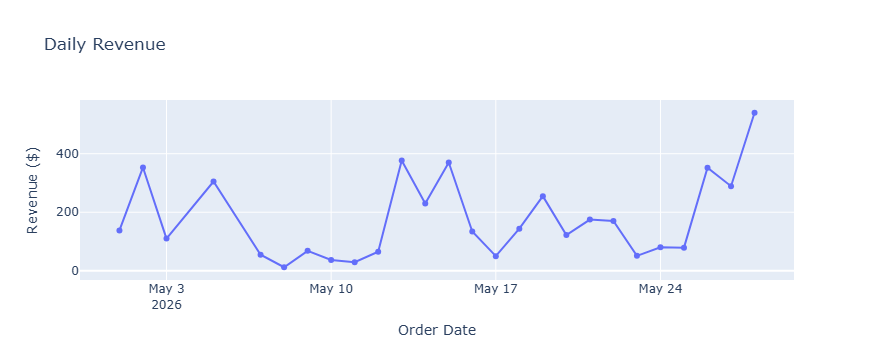

In [12]:
import pandas as pd
import plotly.express as px

# Query Gold aggregated data
gold_df = pd.read_sql_query(
    "SELECT order_date, SUM(revenue) AS revenue FROM gold_daily_product_revenue GROUP BY order_date ORDER BY order_date",
    conn,
)

# Build line chart
fig = px.line(gold_df, x="order_date", y="revenue", markers=True, title="Daily Revenue")
fig.update_layout(xaxis_title="Order Date", yaxis_title="Revenue ($)", hovermode="x unified")
fig.show()

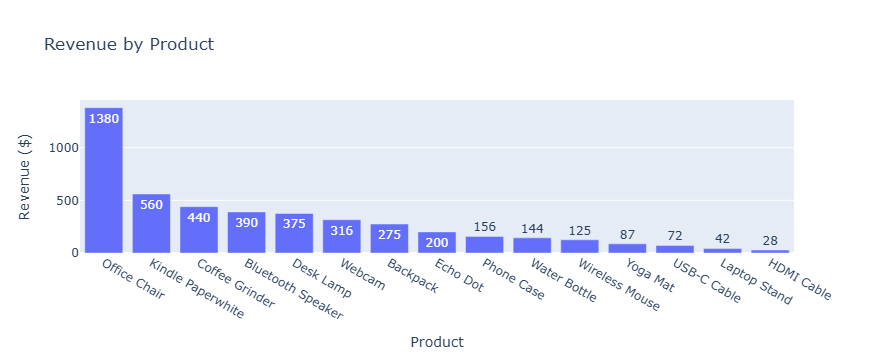

In [13]:
import pandas as pd
import plotly.express as px

# Query Gold product revenue data
gold_df = pd.read_sql_query(
    "SELECT product, SUM(revenue) AS revenue FROM gold_daily_product_revenue GROUP BY product ORDER BY revenue DESC",
    conn,
)

# Build bar chart
fig = px.bar(gold_df, x="product", y="revenue", title="Revenue by Product", text="revenue")
fig.update_layout(xaxis_title="Product", yaxis_title="Revenue ($)")
fig.show()